# notebook version of python file with same name

In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import torch

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.rl import evaluate_terminal_reward_models as etm
# or: from src.rl.evaluate_terminal_reward_models import load_sarsa_critic

from src.rl.evaluate_terminal_reward_models import load_data, load_sarsa_critic, \
    load_data,load_actor_and_critic, get_steps_to_go, generate_model_outputs, \
    _bin_and_average

SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/terminal_reward_zero_dose_advantage"
os.makedirs(SAVE_DIR, exist_ok=True)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# load terminal sarsa model
terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams = load_sarsa_critic(reward_type='terminal')

# load health_score sarsa model
health_score_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = load_sarsa_critic(shifted_actions=True, reward_type='health_score_change')

# load terminal cql model
terminal_cql_model_dir = Path("/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_log_probs/split_0/sepsis/intake-vis/terminal_only/final_model_terminal_discount_0.998/choc_cql_with_logprobs_intake-vis_random_search_standard_20260726_214042/unknown_cx3-20-3_20260727-131356_d435c879")
terminal_cql_actor, terminal_cql_critic, terminal_cql_config_manager, terminal_cql_hyperparams = load_actor_and_critic(model_dir = terminal_cql_model_dir, model_type='cql')

# load health_score cql model
health_score_model_dir = Path("/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_log_probs/split_0/sepsis/intake-vis/health_score_change_only/discount_0.975/best_runs/unknown_cx3-20-1_20260722-133922_72b7d74b")
health_score_cql_actor, health_score_cql_critic, health_score_cql_config_manager, health_score_cql_hyperparams = load_actor_and_critic(
    model_dir = health_score_model_dir, 
    model_type='cql'
)

Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/terminal_only/final_model_terminal_discount_0.998/choc_basic_q_intake-vis_fixed_hyperparameters_standard_20260724_215318/config_manager.pkl
Detected environment: local
Checking experiments_dir: /home/jake/Documents/AI_Clinician/experiments
Ensured experiments_dir exists: /home/jake/Documents/AI_Clinician/experiments
Using supervised_final_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/
Using bc_transformer_final_model_dir: /home/jake/Documents/AI_Clinician/models/bc_transformer/choc/
Using rl_models_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/
Verified data_dir exists: /home/jake/Documents/AI_Clinician/choc_data
Verified code_dir exists: /home/jake/Documents/AI_Clinician/choc_code
Using config_dir: /home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/config
Loading config manager from: /home/jake/Documents/AI_Cl

In [3]:
processors = {}
processors['train'], processors['test'] = load_data(terminal_sarsa_config_manager, terminal_sarsa_hyperparams)  

Using terminal reward type
Using terminal reward type


# computing signal penalty decomposition for zero vaso doses

In [7]:
split = 'test'
processor = processors[split]
# get and create actions
clinician_actions = processor.rl_dataset["actions"]

# vaso is second column of actions, find the non-zero indices of the vaso column
vaso_actions = clinician_actions[:, 1]
non_zero_indices = torch.nonzero(vaso_actions).squeeze()

# zero_vaso_actions created by simply setting the vaso column to zero
zero_vaso_actions = clinician_actions.clone()
zero_vaso_actions[:, 1] = 0

In [11]:
# generate q values for each model
q_cql_terminal_real = generate_model_outputs(
    processor, 
    model=terminal_cql_critic, 
    actions_to_use=clinician_actions, 
    model_type="critic", 
    reduction='mean',
)

q_cql_terminal_zero = generate_model_outputs(
    processor, 
    model=terminal_cql_critic, 
    actions_to_use=zero_vaso_actions, 
    model_type="critic", 
    reduction='mean',
)

sarsa_terminal_real = generate_model_outputs(
    processor, 
    model=terminal_sarsa_critic, 
    actions_to_use=clinician_actions, 
    model_type="critic", 
    reduction='mean',
)

sarsa_terminal_zero = generate_model_outputs(
    processor, 
    model=terminal_sarsa_critic, 
    actions_to_use=zero_vaso_actions, 
    model_type="critic", 
    reduction='mean',
)

q_cql_health_score_real = generate_model_outputs(
    processor, 
    model=health_score_cql_critic, 
    actions_to_use=clinician_actions, 
    model_type="critic", 
    reduction='mean',
)

q_cql_health_score_zero = generate_model_outputs(
    processor, 
    model=health_score_cql_critic, 
    actions_to_use=zero_vaso_actions, 
    model_type="critic", 
    reduction='mean',
)

q_sarsa_health_score_real = generate_model_outputs(
    processor, 
    model=health_score_critic, 
    actions_to_use=clinician_actions, 
    model_type="critic", 
    reduction='mean',
)

q_sarsa_health_score_zero = generate_model_outputs(
    processor, 
    model=health_score_critic, 
    actions_to_use=zero_vaso_actions, 
    model_type="critic", 
    reduction='mean',
)



In [6]:
print(f"q_cql_terminal_real: mean={q_cql_terminal_real.mean():.4f}, std={q_cql_terminal_real.std():.4f}")
print(f"q_cql_terminal_zero: mean={q_cql_terminal_zero.mean():.4f}, std={q_cql_terminal_zero.std():.4f}")
print(f"q_sarsa_terminal_real: mean={sarsa_terminal_real.mean():.4f}, std={sarsa_terminal_real.std():.4f}")
print(f"q_sarsa_terminal_zero: mean={sarsa_terminal_zero.mean():.4f}, std={sarsa_terminal_zero.std():.4f}")
print(f"q_cql_health_score_real: mean={q_cql_health_score_real.mean():.4f}, std={q_cql_health_score_real.std():.4f}")
print(f"q_cql_health_score_zero: mean={q_cql_health_score_zero.mean():.4f}, std={q_cql_health_score_zero.std():.4f}")
print(f"q_sarsa_health_score_real: mean={q_sarsa_health_score_real.mean():.4f}, std={q_sarsa_health_score_real.std():.4f}")
print(f"q_sarsa_health_score_zero: mean={q_sarsa_health_score_zero.mean():.4f}, std={q_sarsa_health_score_zero.std():.4f}")

q_cql_terminal_real: mean=4.8257, std=3.1410
q_cql_terminal_zero: mean=4.8569, std=3.1066
q_sarsa_terminal_real: mean=5.0532, std=3.1223
q_sarsa_terminal_zero: mean=5.0506, std=3.1245
q_cql_health_score_real: mean=-6.1548, std=2.1700
q_cql_health_score_zero: mean=-6.1504, std=2.1705
q_sarsa_health_score_real: mean=0.6306, std=1.1424
q_sarsa_health_score_zero: mean=0.6534, std=1.1324


In [7]:
# get std of q values for sarsa real models
sarsa_terminal_real_std = torch.std(sarsa_terminal_real)
print(f"Standard deviation of SARSA terminal real q values: {sarsa_terminal_real_std}")
sarsa_health_score_real_std = torch.std(q_sarsa_health_score_real)
print(f"Standard deviation of SARSA health score real q values: {sarsa_health_score_real_std}")

Standard deviation of SARSA terminal real q values: 3.122340440750122
Standard deviation of SARSA health score real q values: 1.1424229145050049


In [ ]:
def z(x, ref):
    mu, sigma = ref.mean(), ref.std().clamp(min=1e-6)
    return (x - mu) / sigma

@torch.no_grad()
def compute_signal_penalty_decomposition(
        q_cql_real_full, q_cql_zero_full,
        q_sarsa_real_full, q_sarsa_zero_full,
        non_zero_indices,
    ):
    """
    Decomposes CQL's zero-vs-real advantage into two components:
      - signal: how much the UNPENALIZED (SARSA) critic thinks the real
                dose beats zero (Q_sarsa_zero - Q_sarsa_real)
      - delta_penalty: how much MORE CQL suppresses the real dose relative
                to zero, compared to SARSA (i.e. the differential effect
                of CQL's conservative penalty specifically on the real,
                rarer action vs. the common zero action)

    These should satisfy: advantage_cql ≈ signal + delta_penalty

    All four input Q arrays are expected on the FULL test set; this
    function applies `non_zero_indices` internally to restrict the
    analysis to timesteps where the clinician actually gave a real vaso
    dose (zero-vaso timesteps are excluded since they trivially collapse
    the counterfactual and dilute the effect).

    `scale` should be computed on the FULL test set (not the restricted
    subset) so it reflects the critic's overall Q-spread, not just the
    spread within this particular slice.    """


    # each critic's own reference distribution = its Q over real (clinician) actions, full test set
    q_cql_real_z = z(q_cql_real_full, q_cql_real_full)
    q_cql_zero_z = z(q_cql_zero_full, q_cql_real_full)   # same critic's reference stats
    q_sarsa_real_z = z(q_sarsa_real_full, q_sarsa_real_full)
    q_sarsa_zero_z = z(q_sarsa_zero_full, q_sarsa_real_full)  # same critic's reference stats

    q_cql_real = q_cql_real_z[non_zero_indices]
    q_cql_zero = q_cql_zero_z[non_zero_indices]
    q_sarsa_real = q_sarsa_real_z[non_zero_indices]
    q_sarsa_zero = q_sarsa_zero_z[non_zero_indices]

    signal = q_sarsa_real - q_sarsa_zero
    penalty_real = q_cql_real - q_sarsa_real
    penalty_zero = q_cql_zero - q_sarsa_zero
    delta_penalty = penalty_real - penalty_zero
    advantage_cql = q_cql_real - q_cql_zero

    reconstructed = signal + delta_penalty
    reconstruction_error = (advantage_cql - reconstructed).abs().mean().item()

    return {
        "signal": signal.cpu().numpy(),
        "delta_penalty": delta_penalty.cpu().numpy(),
        "advantage_cql": advantage_cql.cpu().numpy(),
        "reconstructed_advantage": reconstructed.cpu().numpy(),
        "reconstruction_error": reconstruction_error,
    }

In [9]:
z_q_cql_health_score_real = z(q_cql_health_score_real, q_cql_health_score_real)
z_q_cql_health_score_zero = z(q_cql_health_score_zero, q_cql_health_score_real)

z_q_sarsa_health_score_real = z(q_sarsa_health_score_real, q_sarsa_health_score_real)
z_q_sarsa_health_score_zero = z(q_sarsa_health_score_zero, q_sarsa_health_score_real)

z_diff_health_score_real = z_q_cql_health_score_real[non_zero_indices] - z_q_sarsa_health_score_real[non_zero_indices]
z_diff_health_score_real_mean = z_diff_health_score_real.mean().item()

print(f"Mean of z-difference (CQL health score real - Sarsa health score real): {z_diff_health_score_real_mean:.4f}")

z_diff_health_score_zero = z_q_cql_health_score_zero[non_zero_indices] - z_q_sarsa_health_score_zero[non_zero_indices]
z_diff_health_score_zero_mean = z_diff_health_score_zero.mean().item()

print(f"Mean of z-difference (CQL health score zero - Sarsa health score zero): {z_diff_health_score_zero_mean:.4f}")

Mean of z-difference (CQL health score real - Sarsa health score real): 1.0030
Mean of z-difference (CQL health score zero - Sarsa health score zero): 0.7721


In [10]:
z_q_cql_terminal_real = z(q_cql_terminal_real, q_cql_terminal_real)
z_q_cql_terminal_zero = z(q_cql_terminal_zero, q_cql_terminal_real)

z_q_sarsa_terminal_real = z(sarsa_terminal_real , sarsa_terminal_real)
z_q_sarsa_terminal_zero = z(sarsa_terminal_zero, sarsa_terminal_real)

z_diff_terminal_real = z_q_cql_terminal_real[non_zero_indices] - z_q_sarsa_terminal_real[non_zero_indices]
z_diff_terminal_real_mean = z_diff_terminal_real.mean().item()

print(f"Mean of z-difference (CQL terminal real - Sarsa terminal real): {z_diff_terminal_real_mean:.4f}")

z_diff_terminal_zero = z_q_cql_terminal_zero[non_zero_indices] - z_q_sarsa_terminal_zero[non_zero_indices]
z_diff_terminal_zero_mean = z_diff_terminal_zero.mean().item()

print(f"Mean of z-difference (CQL terminal zero - Sarsa terminal zero): {z_diff_terminal_zero_mean:.4f}")

Mean of z-difference (CQL terminal real - Sarsa terminal real): -0.0821
Mean of z-difference (CQL terminal zero - Sarsa terminal zero): 0.0560


In [11]:
decomp_terminal = compute_signal_penalty_decomposition(
    q_cql_real_full=q_cql_terminal_real,
    q_cql_zero_full=q_cql_terminal_zero,
    q_sarsa_real_full=sarsa_terminal_real,
    q_sarsa_zero_full=sarsa_terminal_zero,
    non_zero_indices=non_zero_indices,
)

decomp_health_score = compute_signal_penalty_decomposition(
    q_cql_real_full=q_cql_health_score_real,
    q_cql_zero_full=q_cql_health_score_zero,
    q_sarsa_real_full=q_sarsa_health_score_real,
    q_sarsa_zero_full=q_sarsa_health_score_zero,
    non_zero_indices=non_zero_indices,
)

print(f"Terminal: reconstruction error = {decomp_terminal['reconstruction_error']:.6f}, "
      f"mean |advantage| = {np.abs(decomp_terminal['advantage_cql']).mean():.6f}")
print(f"Health-score: reconstruction error = {decomp_health_score['reconstruction_error']:.6f}, "
      f"mean |advantage| = {np.abs(decomp_health_score['advantage_cql']).mean():.6f}")

Terminal: reconstruction error = 0.000000, mean |advantage| = 0.127554
Health-score: reconstruction error = 0.000000, mean |advantage| = 0.043825


In [12]:
def summarize_decomposition(decomp, label):
    print(f"\n--- {label} ---")
    print(f"signal:        mean={decomp['signal'].mean():.4f}, std={decomp['signal'].std():.4f}")
    print(f"delta_penalty: mean={decomp['delta_penalty'].mean():.4f}, std={decomp['delta_penalty'].std():.4f}")
    print(f"advantage_cql: mean={decomp['advantage_cql'].mean():.4f}, std={decomp['advantage_cql'].std():.4f}")
    print(f"n = {len(decomp['signal'])}")

summarize_decomposition(decomp_terminal, "Terminal reward")
summarize_decomposition(decomp_health_score, "Health-score reward")


--- Terminal reward ---
signal:        mean=0.0106, std=0.0094
delta_penalty: mean=-0.1382, std=0.0805
advantage_cql: mean=-0.1275, std=0.0753
n = 15180

--- Health-score reward ---
signal:        mean=-0.2565, std=0.2217
delta_penalty: mean=0.2309, std=0.2066
advantage_cql: mean=-0.0256, std=0.0886
n = 15180


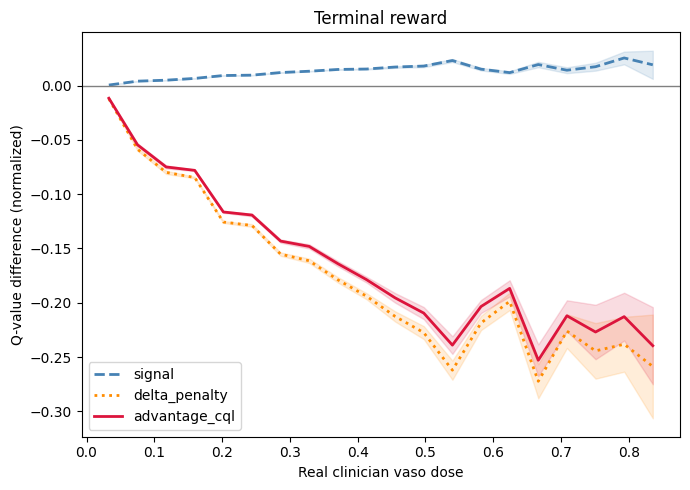

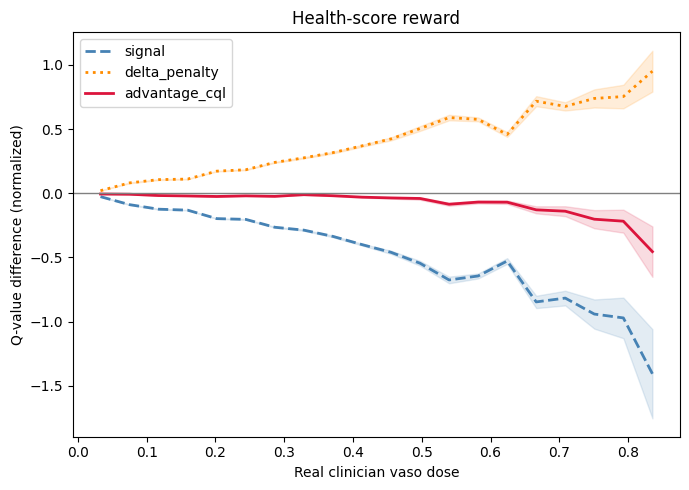

In [13]:
real_dose_nonzero = clinician_actions[non_zero_indices, 1].cpu().numpy()

def plot_decomposition_by_dose(decomp, real_dose, label, n_bins=20, save_path=None):
    fig, ax = plt.subplots(figsize=(7, 5))

    for key, color, ls in [
        ("signal", "steelblue", "--"),
        ("delta_penalty", "darkorange", ":"),
        ("advantage_cql", "crimson", "-"),
    ]:
        centers, means, sems, _ = _bin_and_average(real_dose, decomp[key], n_bins)
        ax.plot(centers, means, color=color, ls=ls, lw=2, label=key)
        ax.fill_between(centers, means - sems, means + sems, color=color, alpha=0.15)

    ax.axhline(0, color='gray', lw=1)
    ax.set_xlabel("Real clinician vaso dose")
    ax.set_ylabel("Q-value difference (normalized)")
    ax.set_title(label)
    ax.legend()
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()

plot_decomposition_by_dose(decomp_terminal, real_dose_nonzero, "Terminal reward", save_path=os.path.join(SAVE_DIR, "decomp_terminal.png"))
plot_decomposition_by_dose(decomp_health_score, real_dose_nonzero, "Health-score reward", save_path=os.path.join(SAVE_DIR, "decomp_health_score.png"))

# action sensitivity

In [8]:
def action_sensitivity_sweep(
        processor,
        model,
        clinician_actions,
        vaso_dim=1,
        fluid_dim=0,
        n_grid=20,
        fluid_mode="clinician",   # "clinician" (real fluid dose) or "zero" (fixed at 0)
        batch_size=1024,
        device="cuda" if torch.cuda.is_available() else "cpu",
    ):
    """
    Sweeps vaso dose across a grid of values (holding fluid at either the
    clinician's real dose or a fixed value), generating Q-values at each
    grid point via generate_model_outputs — same pattern as the rest of
    the pipeline. Returns Q at each grid point, per timestep, plus the
    resulting per-timestep range (max - min across the grid).
    """
    vaso_grid = torch.linspace(0, 1, n_grid)
    q_at_grid = []

    for vaso_val in vaso_grid:
        swept_actions = clinician_actions.clone()
        swept_actions[:, vaso_dim] = vaso_val
        if fluid_mode == "zero":
            swept_actions[:, fluid_dim] = 0.0
        # if fluid_mode == "clinician", fluid stays at its real cloned value — no change needed

        q_vals = generate_model_outputs(
            processor,
            model=model,
            actions_to_use=swept_actions,
            model_type="critic",
            reduction='mean',
            batch_size=batch_size,
            device=device,
        )
        q_at_grid.append(q_vals)

    q_at_grid = torch.stack(q_at_grid, dim=1)  # (n_timesteps, n_grid)
    q_range = q_at_grid.max(dim=1).values - q_at_grid.min(dim=1).values

    return {
        "q_at_grid": q_at_grid,     # (n_timesteps, n_grid) — full sweep, if you want finer analysis later
        "q_range": q_range,         # (n_timesteps,) — per-timestep action-sensitivity
        "vaso_grid": vaso_grid,
    }

In [9]:
def normalize_sensitivity(q_range, reference_q_real):
    """
    Expresses per-timestep action-sensitivity (q_range) as a percentage
    of the reference critic's overall between-state Q spread (IQR),
    computed at real clinician actions — puts sensitivity on a comparable
    scale across critics/reward arms with very different absolute Q scales.
    """
    q25, q75 = torch.quantile(reference_q_real, 0.25), torch.quantile(reference_q_real, 0.75)
    ref_iqr = (q75 - q25).clamp(min=1e-6)
    return (q_range / ref_iqr * 100).cpu().numpy()

In [12]:
sens_sarsa_terminal = action_sensitivity_sweep(processor, terminal_sarsa_critic, clinician_actions, fluid_mode="clinician")
sens_sarsa_health_score = action_sensitivity_sweep(processor, health_score_critic, clinician_actions, fluid_mode="clinician")

pct_sarsa_terminal = normalize_sensitivity(sens_sarsa_terminal["q_range"], sarsa_terminal_real)
pct_sarsa_health_score = normalize_sensitivity(sens_sarsa_health_score["q_range"], q_sarsa_health_score_real)

print(f"Terminal SARSA: median action-sweep range = {np.median(pct_sarsa_terminal):.1f}% of state-wise Q IQR")
print(f"Health-score SARSA: median action-sweep range = {np.median(pct_sarsa_health_score):.1f}% of state-wise Q IQR")

Terminal SARSA: median action-sweep range = 2.9% of state-wise Q IQR
Health-score SARSA: median action-sweep range = 71.3% of state-wise Q IQR


In [15]:
# calculate difference between first and last columns of q_at_grid for health_score SARSA
q_diff = sens_sarsa_terminal['q_at_grid'][:, 1] - sens_sarsa_terminal['q_at_grid'][:, 0]

# get indices of q_diff greater than 0
q_diff_indices = np.where(q_diff.cpu() > 0)[0]
q_diff_indices.shape

(193020,)

In [17]:
# calculate difference between first and last columns of q_at_grid for health_score SARSA
q_diff = sens_sarsa_health_score['q_at_grid'][:, 2] - sens_sarsa_health_score['q_at_grid'][:, 1]

# get indices of q_diff greater than 0
q_diff_indices = np.where(q_diff.cpu() > 0)[0]
q_diff_indices

array([], dtype=int64)

In [13]:
"""
Plot: action-sensitivity comparison, terminal-reward vs health-score-reward SARSA critics.

Two panels:
  (A) Distribution of per-timestep normalized action-sweep range (% of state-wise Q IQR)
      for terminal vs health-score critics — shows the terminal critic's Q is nearly
      flat as vaso dose is swept, while the health-score critic's Q moves substantially.
  (B) A handful of individual Q-vs-vaso-dose curves for each critic, normalized to each
      timestep's own IQR-relative scale, so the "flat vs steep" shape is visible directly
      rather than just summarized as a single number.

Expects the following already computed in your session (as in your sweep code):
    sens_sarsa_terminal, sens_sarsa_health_score   # dicts from action_sensitivity_sweep
    pct_sarsa_terminal, pct_sarsa_health_score     # arrays from normalize_sensitivity
    sarsa_terminal_real, q_sarsa_health_score_real # reference Q distributions used for IQR
"""

import numpy as np
import matplotlib.pyplot as plt
import torch

TERMINAL_COLOR = "#c0392b"
HEALTH_COLOR = "#2471a3"


def plot_action_sensitivity_comparison(
    sens_sarsa_terminal,
    sens_sarsa_health_score,
    pct_sarsa_terminal,
    pct_sarsa_health_score,
    sarsa_terminal_real,
    q_sarsa_health_score_real,
    n_example_curves=50,
    seed=0,
):
    rng = np.random.default_rng(seed)

    fig, (ax_dist, ax_curves) = plt.subplots(1, 2, figsize=(12, 5.2))

    # ---------- Panel A: distribution comparison ----------
    data = [pct_sarsa_terminal, pct_sarsa_health_score]
    labels = ["Terminal reward\n(SARSA)", "Health-score reward\n(SARSA)"]
    colors = [TERMINAL_COLOR, HEALTH_COLOR]

    parts = ax_dist.violinplot(data, showmedians=False, showextrema=False, widths=0.8)
    for pc, c in zip(parts["bodies"], colors):
        pc.set_facecolor(c)
        pc.set_alpha(0.35)
        pc.set_edgecolor(c)

    bp = ax_dist.boxplot(
        data,
        widths=0.15,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(color="black", linewidth=2),
    )
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.85)

    for i, d in enumerate(data, start=1):
        med = np.median(d)
        ax_dist.annotate(
            f"median = {med:.1f}%",
            xy=(i, med),
            xytext=(i + 0.28, med),
            fontsize=10,
            va="center",
            fontweight="bold",
            color=colors[i - 1],
        )

    ax_dist.set_xticks([1, 2])
    ax_dist.set_xticklabels(labels)
    ax_dist.set_ylabel("Action-sweep Q range\n(% of state-wise Q IQR)")
    ax_dist.set_title("A. Vaso-dose sensitivity of learned Q,\nby reward formulation", fontsize=11)
    ax_dist.set_ylim(bottom=0)
    ax_dist.spines[["top", "right"]].set_visible(False)
    ax_dist.grid(axis="y", alpha=0.25)

    # ---------- Panel B: example Q-vs-dose curves ----------
    def _prep_curves(sens, reference_q_real):
        vaso_grid = sens["vaso_grid"]
        if torch.is_tensor(vaso_grid):
            vaso_grid = vaso_grid.cpu().numpy()
        q_at_grid = sens["q_at_grid"]
        if torch.is_tensor(q_at_grid):
            q_at_grid = q_at_grid.cpu().numpy()
        q25, q75 = np.quantile(reference_q_real.cpu().numpy() if torch.is_tensor(reference_q_real) else reference_q_real, [0.25, 0.75])
        iqr = max(q75 - q25, 1e-6)
        # normalize each curve by subtracting its own mean, scaling by the shared IQR
        # so curve *shape/amplitude* is comparable across critics with different absolute scales
        centered = q_at_grid - q_at_grid.mean(axis=1, keepdims=True)
        normed = centered / iqr * 100
        return vaso_grid, normed

    vaso_grid_t, curves_t = _prep_curves(sens_sarsa_terminal, sarsa_terminal_real)
    vaso_grid_h, curves_h = _prep_curves(sens_sarsa_health_score, q_sarsa_health_score_real)

    idx_t = rng.choice(curves_t.shape[0], size=min(n_example_curves, curves_t.shape[0]), replace=False)
    idx_h = rng.choice(curves_h.shape[0], size=min(n_example_curves, curves_h.shape[0]), replace=False)

    for j, i in enumerate(idx_t):
        ax_curves.plot(vaso_grid_t, curves_t[i], color=TERMINAL_COLOR, alpha=0.6, linewidth=1.3,
                        label="Terminal reward" if j == 0 else None)
    for j, i in enumerate(idx_h):
        ax_curves.plot(vaso_grid_h, curves_h[i], color=HEALTH_COLOR, alpha=0.6, linewidth=1.3,
                        label="Health-score reward" if j == 0 else None)

    ax_curves.axhline(0, color="grey", linewidth=0.8, linestyle="--", alpha=0.6)
    ax_curves.set_xlabel("Swept vasopressor dose (normalized)")
    ax_curves.set_ylabel("Q, centered per-timestep\n(% of state-wise Q IQR)")
    ax_curves.set_title(f"B. Example Q(state, dose) curves\n({len(idx_t)} random timesteps per critic)", fontsize=11)
    ax_curves.legend(loc="upper right", frameon=False, fontsize=9)
    ax_curves.spines[["top", "right"]].set_visible(False)
    ax_curves.grid(axis="y", alpha=0.25)

    fig.suptitle(
        "Terminal-reward critics are nearly action-insensitive; health-score critics are not",
        fontsize=12, fontweight="bold", y=1.02,
    )
    fig.tight_layout()
    save_path = os.path.join(SAVE_DIR, "action_sensitivity_comparison.png")
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved to {save_path}")
    # close
    plt.close()
    return fig



Saved to /home/jake/Documents/AI_Clinician/models/analysis/terminal_reward_zero_dose_advantage/action_sensitivity_comparison.png


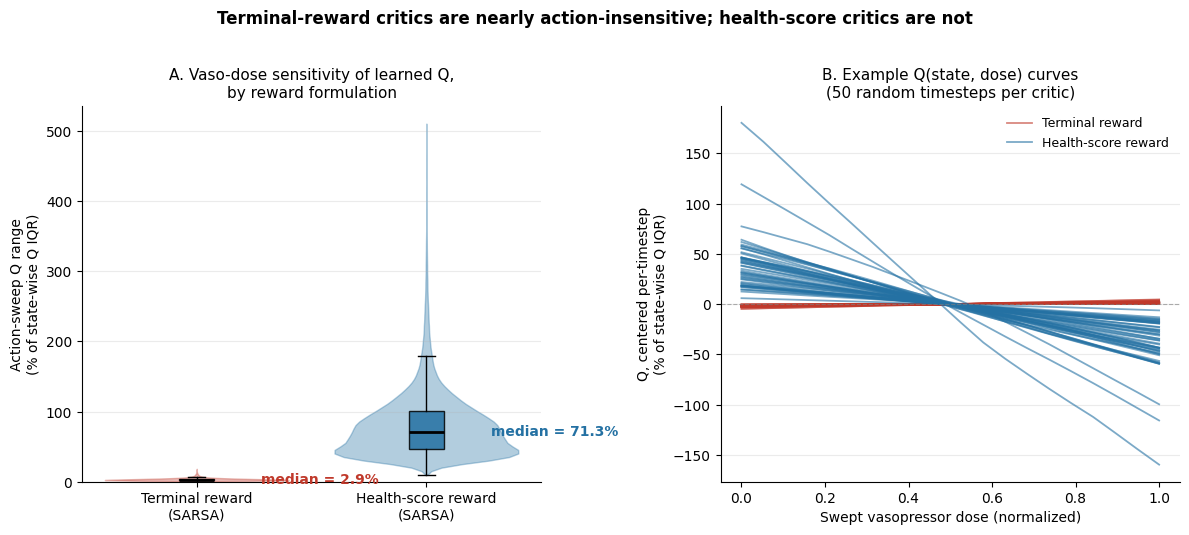

In [14]:
plot_action_sensitivity_comparison(
    sens_sarsa_terminal,
    sens_sarsa_health_score,
    pct_sarsa_terminal,
    pct_sarsa_health_score,
    sarsa_terminal_real,
    q_sarsa_health_score_real,
)

In [ ]:
split = 'test'
processor = processors[split]
# get and create actions
clinician_actions = processor.rl_dataset["actions"]

# create zero fluid actions. We don't need zero vaso because that's what the policy outputs
zero_fluid_actions = torch.zeros_like(clinician_actions)
zero_fluid_actions[:, 1] = clinician_actions[:, 1]

# get mortality
mortality = processor.rl_dataset["mortality"]

# calculate steps to go
steps_to_go = get_steps_to_go(processor)

### calculate correlations and plot for each critic and action variant ###############
clinician_actions_np = clinician_actions.cpu().numpy() if torch.is_tensor(clinician_actions) else clinician_actions
mortality_np = mortality.cpu().numpy() if torch.is_tensor(mortality) else mortality
steps_to_go_np = steps_to_go.cpu().numpy() if torch.is_tensor(steps_to_go) else steps_to_go

dose_dim = {"zero_vaso": 1, "actor_fluid": 0, "zero_fluid": 0}  # action index per variant

# generate policy actions from the terminal cql actor
batch_size = health_score_sarsa_hyperparams['batch_size']
cql_actor_actions = generate_model_outputs(
    processor=processor, 
    batch_size=batch_size, 
    model=terminal_cql_actor,
    model_type="actor",
    device=device
)

# confirm the policy is recommending zero vaso
assert torch.all(cql_actor_actions[:, 1] == 0), "CQL actor is not recommending zero vaso for all states."

clin_fluid_actor_vaso = clinician_actions.clone()
clin_fluid_actor_vaso[:, 1] = cql_actor_actions[:, 1]
actor_fluid_clin_vaso = clinician_actions.clone()
actor_fluid_clin_vaso[:, 0] = cql_actor_actions[:, 0]

# organize the actions and critics into dictionaries for easy access
action_variants = {
    "clinician":   clinician_actions,       # baseline
    "zero_vaso":   clin_fluid_actor_vaso,  # == actor's vaso prediction, confirmed near-identical
    "actor_fluid": actor_fluid_clin_vaso,
    "zero_fluid":  zero_fluid_actions,
}

critics = {
    "cql_terminal": terminal_cql_critic,
    "sarsa_terminal": terminal_sarsa_critic,
    "sarsa_health_score": health_score_critic,
}

q_values = {}
for critic_name, critic in critics.items():
    q_values[critic_name] = {}
    for variant_name, actions in action_variants.items():
        q_values[critic_name][variant_name] = generate_model_outputs(
            processor=processor,
            batch_size=batch_size,
            model=critic,
            actions_to_use=actions if variant_name != "clinician" else None,
            model_type="critic",
            reduction='mean',
            device=device,
        )

# calculate advantages for each critic and action variant
advantages = {}
for critic_name in critics.keys():
    advantages[critic_name] = {}
    for variant_name in [k for k in action_variants.keys() if k != "clinician"]:
        advantages[critic_name][variant_name] = q_values[critic_name][variant_name] - q_values[critic_name]["clinician"]

Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2392, 0.0764], device='cuda:0')
Action std: tensor([0.2343, 0.0820], device='cuda:0')
Action std: tensor([0.2343, 0.0820], device='cuda:0')
Action std: tensor([0.2343, 0.0820], device='cuda:0')
Action std: tensor([0.2343, 0.0820], device='cuda:0')
Action std: tensor([0.2343, 0.0820], device='cuda:0')
Action std: tensor([0.2343, 

In [51]:
clinician_vaso = clinician_actions[:, 1]
# get indices of vaso dose greater than 0.1
point_one_dose_indices = torch.where(clinician_vaso > 0.1)[0]
point_one_dose_indices.shape

for critic_name, critic in critics.items():
    for variant_name, actions in action_variants.items():
        print(f"{critic_name} - {variant_name} q values mean: {q_values[critic_name][variant_name].mean()}")
        # print(f"{critic_name} - {variant_name} q values median: {q_values[critic_name][variant_name].median()}")

        q_high_vaso = q_values[critic_name][variant_name][point_one_dose_indices]
        print(f"{critic_name} - {variant_name} q values for patients with clinician vaso dose > 0.1 mean: {q_high_vaso.mean()}")

        if variant_name != "clinician":
            print(f"{critic_name} - {variant_name} advantages mean: {advantages[critic_name][variant_name].mean()}")
            # print(f"{critic_name} - {variant_name} advantages median: {advantages[critic_name][variant_name].median()}")
               
        print('\n\n')

cql_terminal - clinician q values mean: 4.825725555419922
cql_terminal - clinician q values for patients with clinician vaso dose > 0.1 mean: 1.3006294965744019



cql_terminal - zero_vaso q values mean: 4.85691499710083
cql_terminal - zero_vaso q values for patients with clinician vaso dose > 0.1 mean: 1.7157413959503174
cql_terminal - zero_vaso advantages mean: 0.031188994646072388



cql_terminal - actor_fluid q values mean: 4.944729328155518
cql_terminal - actor_fluid q values for patients with clinician vaso dose > 0.1 mean: 1.40251886844635
cql_terminal - actor_fluid advantages mean: 0.1190032809972763



cql_terminal - zero_fluid q values mean: 4.915614128112793
cql_terminal - zero_fluid q values for patients with clinician vaso dose > 0.1 mean: 1.274202823638916
cql_terminal - zero_fluid advantages mean: 0.08988804370164871



sarsa_terminal - clinician q values mean: 5.053181171417236
sarsa_terminal - clinician q values for patients with clinician vaso dose > 0.1 mean: 1.80649

In [46]:
cql_terminal_q_high_vaso = cql_terminal_q_values[point_one_dose_indices]
print(f"CQL terminal q values for patients with clinician vaso dose > 0.1 mean: {cql_terminal_q_high_vaso.mean()}")
print(f"CQL terminal q values for patients with clinician vaso dose > 0.1 median: {cql_terminal_q_high_vaso.median()}")

sarsa_terminal_q_high_vaso = sarsa_terminal_q_values[point_one_dose_indices]
print(f"SARSA terminal q values for patients with clinician vaso dose > 0.1 mean: {sarsa_terminal_q_high_vaso.mean()}")
print(f"SARSA terminal q values for patients with clinician vaso dose > 0.1 median: {sarsa_terminal_q_high_vaso.median()}")

CQL terminal q values for patients with clinician vaso dose > 0.1 mean: 1.3006294965744019
CQL terminal q values for patients with clinician vaso dose > 0.1 median: 2.6583609580993652
SARSA terminal q values for patients with clinician vaso dose > 0.1 mean: 1.8064979314804077
SARSA terminal q values for patients with clinician vaso dose > 0.1 median: 3.1821694374084473


In [47]:
cql_terminal_zero_vaso_q_high_vaso = cql_terminal_zero_vaso_q_values[point_one_dose_indices]
print(f"CQL terminal zero vaso q values for patients with clinician vaso dose > 0.1 mean: {cql_terminal_zero_vaso_q_high_vaso.mean()}")
print(f"CQL terminal zero vaso q values for patients with clinician vaso dose > 0.1 median: {cql_terminal_zero_vaso_q_high_vaso.median()}")

sarsa_terminal_zero_vaso_q_high_vaso = sarsa_terminal_zero_vaso_q_values[point_one_dose_indices]
print(f"SARSA terminal zero vaso q values for patients with clinician vaso dose > 0.1 mean: {sarsa_terminal_zero_vaso_q_high_vaso.mean()}")
print(f"SARSA terminal zero vaso q values for patients with clinician vaso dose > 0.1 median: {sarsa_terminal_zero_vaso_q_high_vaso.median()}")

CQL terminal zero vaso q values for patients with clinician vaso dose > 0.1 mean: 1.7157413959503174
CQL terminal zero vaso q values for patients with clinician vaso dose > 0.1 median: 3.0151877403259277
SARSA terminal zero vaso q values for patients with clinician vaso dose > 0.1 mean: 1.7720425128936768
SARSA terminal zero vaso q values for patients with clinician vaso dose > 0.1 median: 3.1442055702209473


In [32]:
sarsa_health_score_zero_vaso_advantage = advantages["sarsa_health_score"]["zero_vaso"]
print(f"SARSA health score zero vaso advantages mean: {sarsa_health_score_zero_vaso_advantage.mean()}")
print(f"SARSA health score zero vaso advantages median: {sarsa_health_score_zero_vaso_advantage.median()}")

SARSA health score zero vaso advantages mean: 0.02281574346125126
SARSA health score zero vaso advantages median: 0.0
